In [1]:
#!pip install vaderSentiment

In [2]:
#pip install wordcloud

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from colorama import Fore, init
import plotly.express as px

import string
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk import tokenize
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize
from tqdm.notebook import tqdm
from collections import Counter
from wordcloud import WordCloud



nltk.download('vader_lexicon')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('averaged_perceptron_tagger')

import warnings
warnings.filterwarnings('ignore')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\gitika.vyas\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\gitika.vyas\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\gitika.vyas\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\gitika.vyas\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


In [2]:
# Read in data using Windows relative paths
br = pd.read_csv(r'..\data\Books_rating.csv', engine='python', encoding='latin1')
bd = pd.read_csv(r'..\data\books_data.csv', engine='python', encoding='latin1')

In [3]:
# Checking columns in dataset
print(br.columns)
print(bd.columns)

Index(['Id', 'Title', 'Price', 'User_id', 'profileName', 'review/helpfulness',
       'review/score', 'review/time', 'review/summary', 'review/text'],
      dtype='object')
Index(['Title', 'description', 'authors', 'image', 'previewLink', 'publisher',
       'publishedDate', 'infoLink', 'categories', 'ratingsCount'],
      dtype='object')


In [4]:
#Merging both the dataset
books = pd.merge(br,bd, on = 'Title')
books.shape

(3000000, 19)

In [5]:
df = books[['Title','review/score','review/text','authors','categories','ratingsCount']]

In [6]:
df.drop_duplicates(inplace = True)
df.shape

(2617289, 6)

In [7]:
df.isna().sum()

Title               207
review/score          0
review/text           8
authors          350198
categories       465848
ratingsCount    1234897
dtype: int64

In [8]:
#Dropping Null Values
df.dropna(inplace = True)
df.isna().sum()

Title           0
review/score    0
review/text     0
authors         0
categories      0
ratingsCount    0
dtype: int64

In [9]:
df.shape

(1325891, 6)

In [10]:
df['authors'] = df['authors'].str.extract(r'\'(.*)\'')

In [11]:
df['categories'] = df['categories'].str.extract(r'\'(.*)\'')

In [12]:
df['word_count'] = df['review/text'].apply(lambda x: len(x.split(' ')))

In [13]:
df.head()

,Title,review/score,review/text,authors,categories,ratingsCount,word_count
47,The Church of Christ: A Biblical Ecclesiology ...,5.0,With the publication of Everett Ferguson's boo...,Everett Ferguson,Religion,5.0,999
48,The Church of Christ: A Biblical Ecclesiology ...,5.0,Everett Ferguson approaches the subject of ear...,Everett Ferguson,Religion,5.0,86
49,The Church of Christ: A Biblical Ecclesiology ...,4.0,This book is a continual resource. It is so bi...,Everett Ferguson,Religion,5.0,31
50,The Church of Christ: A Biblical Ecclesiology ...,4.0,This is a very useful and thorough text book. ...,Everett Ferguson,Religion,5.0,25
181,Voices from the Farm: Adventures in Community ...,5.0,"Ironically, I grew up in a small town close to...",Rupert Fike,Biography & Autobiography,1.0,196


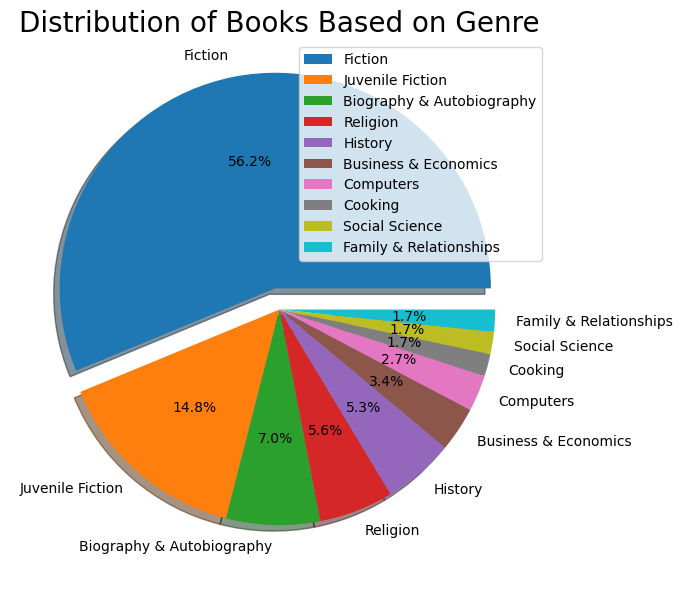

In [14]:
#Distribution of Books Based on Genre
plt.figure(figsize=(7,7))
labels=['Fiction','Juvenile Fiction','Biography & Autobiography','Religion','History','Business & Economics','Computers','Cooking','Social Science','Family & Relationships']
plt.pie(df['categories'].value_counts().head(10),explode=(0.1,0,0,0,0,0,0,0,0,0), labels=labels,autopct='%1.1f%%', shadow=True)
plt.title('Distribution of Books Based on Genre', fontsize = 20)
plt.axis('off')
plt.legend()
plt.show()

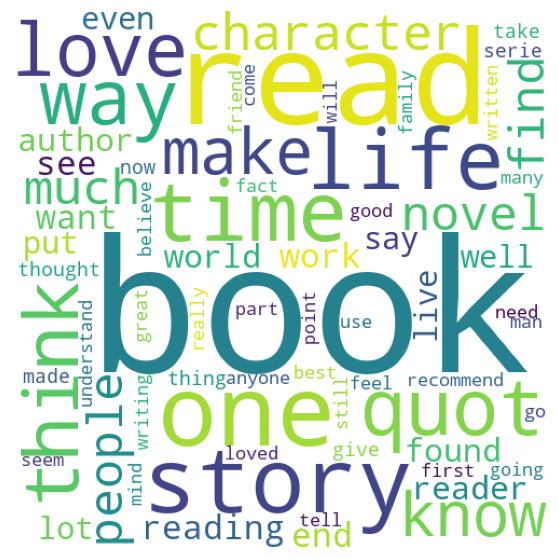

In [15]:
#Wordcloud
from wordcloud import WordCloud

wc = WordCloud(width=500,height=500,min_font_size=15,background_color='white')
spam_wc = wc.generate(df[df['review/score'] > 3]['review/text'].str.cat(sep=" "))

plt.figure(figsize=(7,7))
plt.axis('off')
plt.imshow(spam_wc)

In [16]:
df.rename(columns={'review/text': 'text'}, inplace=True)

In [17]:
#Clean text
stopword = set(stopwords.words('english'))
stemmer = PorterStemmer()

def clean(text):
    text = str(text).lower()
    text = re.sub('\[.*?\]', '', text)
    text = re.sub('https?://\S+|www\.\S+', '', text)
    text = re.sub('<.*?>+', '', text)
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub('\n', '', text)
    text = re.sub('\w*\d\w*', '', text)
    text = [word for word in text.split(' ') if word not in stopword]
    #text = [stemmer.stem(word) for word in text]
    text = " ".join(text)
    
    return text

df['Clean_Text']=df['text'].map(lambda s:clean(s)) 
#df1["Clean_Text"] = df1["Text"].apply(clean)

In [18]:
# Remove symbols from text
df['Clean_Text'] = df['Clean_Text'].apply(lambda text: re.sub(r'[^\w\s]', '', str(text)))

In [19]:
def remove_special_characters(text):
    # Using regular expression to remove non-alphanumeric characters and whitespace
    return re.sub(r'[^a-zA-Z0-9\s]', '', str(text))

# Remove special characters from text
df['Clean_Text'] = df['Clean_Text'].apply(remove_special_characters)

In [20]:
df

,Title,review/score,text,authors,categories,ratingsCount,word_count,Clean_Text
47,The Church of Christ: A Biblical Ecclesiology ...,5.0,With the publication of Everett Ferguson's boo...,Everett Ferguson,Religion,5.0,999,publication everett fergusons book ecclesiolog...
48,The Church of Christ: A Biblical Ecclesiology ...,5.0,Everett Ferguson approaches the subject of ear...,Everett Ferguson,Religion,5.0,86,everett ferguson approaches subject early chri...
49,The Church of Christ: A Biblical Ecclesiology ...,4.0,This book is a continual resource. It is so bi...,Everett Ferguson,Religion,5.0,31,book continual resource biblical simple dr fer...
50,The Church of Christ: A Biblical Ecclesiology ...,4.0,This is a very useful and thorough text book. ...,Everett Ferguson,Religion,5.0,25,useful thorough text book would recommend anyo...
181,Voices from the Farm: Adventures in Community ...,5.0,"Ironically, I grew up in a small town close to...",Rupert Fike,Biography & Autobiography,1.0,196,ironically grew small town close farm never kn...
...,...,...,...,...,...,...,...,...
2999995,The Idea of History,4.0,"This is an extremely difficult book to digest,...",R. G. Collingwood,History,3.0,90,extremely difficult book digest casual readers...
2999996,The Idea of History,4.0,This is pretty interesting. Collingwood seems ...,R. G. Collingwood,History,3.0,103,pretty interesting collingwood seems like firs...
2999997,The Idea of History,4.0,"This is a good book but very esoteric. ""What i...",R. G. Collingwood,History,3.0,28,good book esoteric history eh carr easier sele...
2999998,The Idea of History,5.0,"My daughter, a freshman at Indiana University,...",R. G. Collingwood,History,3.0,47,daughter freshman indiana university emailed l...


In [21]:
(df[['text','Clean_Text']].head(10))

,text,Clean_Text
47,With the publication of Everett Ferguson's boo...,publication everett fergusons book ecclesiolog...
48,Everett Ferguson approaches the subject of ear...,everett ferguson approaches subject early chri...
49,This book is a continual resource. It is so bi...,book continual resource biblical simple dr fer...
50,This is a very useful and thorough text book. ...,useful thorough text book would recommend anyo...
181,"Ironically, I grew up in a small town close to...",ironically grew small town close farm never kn...
182,This book gave me a glimpse at life on The Far...,book gave glimpse life farm described people w...
183,This book contains true accounts from former r...,book contains true accounts former residents p...
184,I really liked hearing from my old friends. Th...,really liked hearing old friends farm great le...
185,Gave me a detailed vision of day to day life i...,gave detailed vision day day life commune stil...
186,Brought back warm memories of my brief stay at...,brought back warm memories brief stay farm lat...


In [22]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()
analyzer = SentimentIntensityAnalyzer()

In [23]:
import numpy as np

# Convert float values to strings
df['Clean_Text'] = df['Clean_Text'].astype(str)

# Apply polarity scores
df['polarity'] = df['Clean_Text'].apply(lambda x: analyzer.polarity_scores(x))
df.head(20)

,Title,review/score,text,authors,categories,ratingsCount,word_count,Clean_Text,polarity
47,The Church of Christ: A Biblical Ecclesiology ...,5.0,With the publication of Everett Ferguson's boo...,Everett Ferguson,Religion,5.0,999,publication everett fergusons book ecclesiolog...,"{'neg': 0.018, 'neu': 0.789, 'pos': 0.193, 'co..."
48,The Church of Christ: A Biblical Ecclesiology ...,5.0,Everett Ferguson approaches the subject of ear...,Everett Ferguson,Religion,5.0,86,everett ferguson approaches subject early chri...,"{'neg': 0.119, 'neu': 0.824, 'pos': 0.058, 'co..."
49,The Church of Christ: A Biblical Ecclesiology ...,4.0,This book is a continual resource. It is so bi...,Everett Ferguson,Religion,5.0,31,book continual resource biblical simple dr fer...,"{'neg': 0.0, 'neu': 0.576, 'pos': 0.424, 'comp..."
50,The Church of Christ: A Biblical Ecclesiology ...,4.0,This is a very useful and thorough text book. ...,Everett Ferguson,Religion,5.0,25,useful thorough text book would recommend anyo...,"{'neg': 0.0, 'neu': 0.649, 'pos': 0.351, 'comp..."
181,Voices from the Farm: Adventures in Community ...,5.0,"Ironically, I grew up in a small town close to...",Rupert Fike,Biography & Autobiography,1.0,196,ironically grew small town close farm never kn...,"{'neg': 0.144, 'neu': 0.627, 'pos': 0.229, 'co..."
182,Voices from the Farm: Adventures in Community ...,5.0,This book gave me a glimpse at life on The Far...,Rupert Fike,Biography & Autobiography,1.0,222,book gave glimpse life farm described people w...,"{'neg': 0.056, 'neu': 0.614, 'pos': 0.33, 'com..."
183,Voices from the Farm: Adventures in Community ...,5.0,This book contains true accounts from former r...,Rupert Fike,Biography & Autobiography,1.0,48,book contains true accounts former residents p...,"{'neg': 0.054, 'neu': 0.491, 'pos': 0.455, 'co..."
184,Voices from the Farm: Adventures in Community ...,4.0,I really liked hearing from my old friends. Th...,Rupert Fike,Biography & Autobiography,1.0,38,really liked hearing old friends farm great le...,"{'neg': 0.11, 'neu': 0.513, 'pos': 0.377, 'com..."
185,Voices from the Farm: Adventures in Community ...,4.0,Gave me a detailed vision of day to day life i...,Rupert Fike,Biography & Autobiography,1.0,24,gave detailed vision day day life commune stil...,"{'neg': 0.0, 'neu': 0.564, 'pos': 0.436, 'comp..."
186,Voices from the Farm: Adventures in Community ...,5.0,Brought back warm memories of my brief stay at...,Rupert Fike,Biography & Autobiography,1.0,44,brought back warm memories brief stay farm lat...,"{'neg': 0.0, 'neu': 0.524, 'pos': 0.476, 'comp..."


In [24]:
#Sentiment analysis
analyzer = SentimentIntensityAnalyzer()

df['Score'] = df['Clean_Text'].apply(lambda text: analyzer.polarity_scores(text)['compound'])

df['Sentiment'] = df['Score'].apply(lambda score: 'positive' if score >= 0.05 else ('negative' if score <= -0.05 else 'neutral'))

print(df[['Clean_Text', 'Score', 'Sentiment']].head())

                                            Clean_Text   Score Sentiment
47   publication everett fergusons book ecclesiolog...  0.9978  positive
48   everett ferguson approaches subject early chri... -0.2431  negative
49   book continual resource biblical simple dr fer...  0.8834  positive
50   useful thorough text book would recommend anyo...  0.6597  positive
181  ironically grew small town close farm never kn...  0.9165  positive


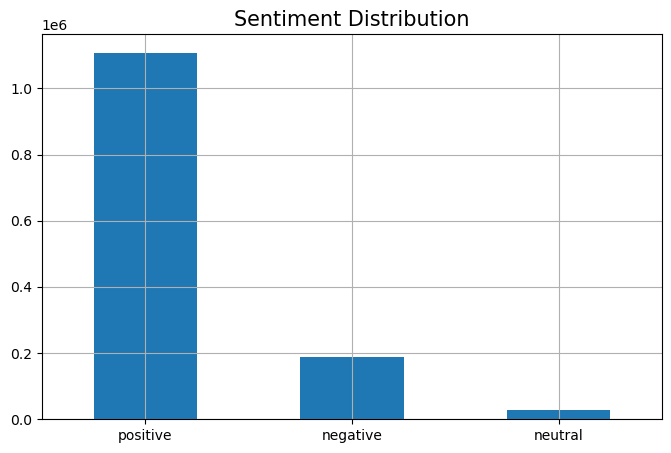

In [26]:
df['Sentiment'].value_counts().plot(kind = 'bar', figsize = (8,5))
plt.xticks(rotation = 'horizontal')
plt.title('Sentiment Distribution',fontsize = 15)
plt.grid()
plt.show()

<Figure size 1200x500 with 0 Axes>

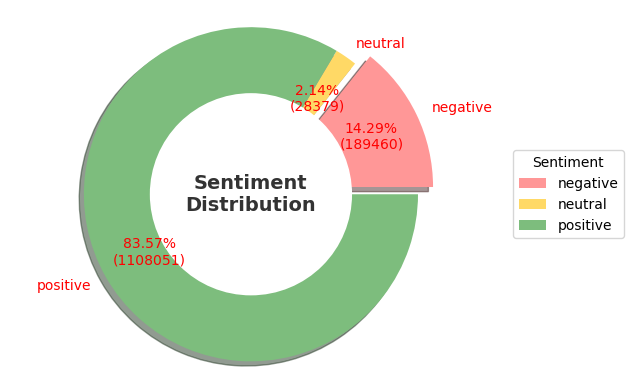

In [29]:
import matplotlib.pyplot as plt

# Create a figure and subplots with 1 row and 2 columns
plt.figure(figsize=(12, 5))

# Plot 1 - Pie chart for sentiment distribution

colors = ['#FF9797', '#FFD966', '#7DBD7D']
explode = (0.1, 0, 0)  
sentiment_counts = df.groupby("Sentiment").size()
fig, ax = plt.subplots()
wedges, texts, autotexts = ax.pie(
    x=sentiment_counts, 
    labels=sentiment_counts.index,
    autopct=lambda p: f'{p:.2f}%\n({int(p*sum(sentiment_counts)/100)})', 
    wedgeprops=dict(width=0.7),
    textprops=dict(size=10, color="r"),  
    pctdistance=0.7,
    colors=colors,
    explode=explode,
    shadow=True)

center_circle = plt.Circle((0, 0), 0.6, color='white', fc='white', linewidth=1.25)
fig.gca().add_artist(center_circle)
ax.text(0, 0, 'Sentiment\nDistribution', ha='center', va='center', fontsize=14, fontweight='bold', color='#333333')
ax.legend(sentiment_counts.index, title="Sentiment", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
ax.axis('equal')  
plt.show()

In [28]:
df['temp_list'] = df['Clean_Text'].apply(lambda x: str(x).split())
top_words = Counter([item for sublist in df['temp_list'] for item in sublist])
top_words_df = pd.DataFrame(top_words.most_common(20), columns=['Common_words', 'count'])

top_words_df.style.background_gradient(cmap='Blues')

,Common_words,count
0,book,2465737
1,read,1037738
2,one,793827
3,story,559010
4,like,524628
5,would,456221
6,books,426911
7,time,394515
8,good,390877
9,great,364292


In [55]:
import nltk
from nltk.tokenize import RegexpTokenizer
tokenizer = RegexpTokenizer(r'\w+')
df['tok_unigram'] = df['Clean_Text'].apply(tokenizer.tokenize)
df.head()

import nltk
from nltk.util import ngrams
def ngramconvert(df,n=3):
    for item in df.columns:
        df['bigram']=df['Clean_Text'].apply(lambda sentence: list(ngrams(sentence.split(), n)))
        return df

df = ngramconvert(df,2)
df.head()

import nltk

from nltk.util import ngrams
def ngramconvert(df,n=3):
    for item in df.columns:
        df['trigram']=df['Clean_Text'].apply(lambda sentence: list(ngrams(sentence.split(), n)))
        return df

df = ngramconvert(df,3)
df.head()

,Title,review/score,text,authors,categories,ratingsCount,word_count,Clean_Text,polarity,compound,Sentiment,temp_list,Score,tok_unigram,bigram,trigram
47,The Church of Christ: A Biblical Ecclesiology ...,5.0,With the publication of Everett Ferguson's boo...,Everett Ferguson,Religion,5.0,999,publication everett fergusons book ecclesiolog...,"{'neg': 0.018, 'neu': 0.789, 'pos': 0.193, 'co...",0.9978,positive,"[publication, everett, fergusons, book, eccles...",0.9978,"[publication, everett, fergusons, book, eccles...","[(The, Church), (Church, of), (of, Christ:), (...","[(The, Church, of), (Church, of, Christ:), (of..."
48,The Church of Christ: A Biblical Ecclesiology ...,5.0,Everett Ferguson approaches the subject of ear...,Everett Ferguson,Religion,5.0,86,everett ferguson approaches subject early chri...,"{'neg': 0.119, 'neu': 0.824, 'pos': 0.058, 'co...",-0.2431,negative,"[everett, ferguson, approaches, subject, early...",-0.2431,"[everett, ferguson, approaches, subject, early...","[(The, Church), (Church, of), (of, Christ:), (...","[(The, Church, of), (Church, of, Christ:), (of..."
49,The Church of Christ: A Biblical Ecclesiology ...,4.0,This book is a continual resource. It is so bi...,Everett Ferguson,Religion,5.0,31,book continual resource biblical simple dr fer...,"{'neg': 0.0, 'neu': 0.576, 'pos': 0.424, 'comp...",0.8834,positive,"[book, continual, resource, biblical, simple, ...",0.8834,"[book, continual, resource, biblical, simple, ...","[(The, Church), (Church, of), (of, Christ:), (...","[(The, Church, of), (Church, of, Christ:), (of..."
50,The Church of Christ: A Biblical Ecclesiology ...,4.0,This is a very useful and thorough text book. ...,Everett Ferguson,Religion,5.0,25,useful thorough text book would recommend anyo...,"{'neg': 0.0, 'neu': 0.649, 'pos': 0.351, 'comp...",0.6597,positive,"[useful, thorough, text, book, would, recommen...",0.6597,"[useful, thorough, text, book, would, recommen...","[(The, Church), (Church, of), (of, Christ:), (...","[(The, Church, of), (Church, of, Christ:), (of..."
181,Voices from the Farm: Adventures in Community ...,5.0,"Ironically, I grew up in a small town close to...",Rupert Fike,Biography & Autobiography,1.0,196,ironically grew small town close farm never kn...,"{'neg': 0.144, 'neu': 0.627, 'pos': 0.229, 'co...",0.9165,positive,"[ironically, grew, small, town, close, farm, n...",0.9165,"[ironically, grew, small, town, close, farm, n...","[(Voices, from), (from, the), (the, Farm:), (F...","[(Voices, from, the), (from, the, Farm:), (the..."


In [56]:
(df[['Clean_Text', 'tok_unigram', 'bigram', 'trigram', 'polarity', 'compound', 'Sentiment']].head(10))

,Clean_Text,tok_unigram,bigram,trigram,polarity,compound,Sentiment
47,publication everett fergusons book ecclesiolog...,"[publication, everett, fergusons, book, eccles...","[(The, Church), (Church, of), (of, Christ:), (...","[(The, Church, of), (Church, of, Christ:), (of...","{'neg': 0.018, 'neu': 0.789, 'pos': 0.193, 'co...",0.9978,positive
48,everett ferguson approaches subject early chri...,"[everett, ferguson, approaches, subject, early...","[(The, Church), (Church, of), (of, Christ:), (...","[(The, Church, of), (Church, of, Christ:), (of...","{'neg': 0.119, 'neu': 0.824, 'pos': 0.058, 'co...",-0.2431,negative
49,book continual resource biblical simple dr fer...,"[book, continual, resource, biblical, simple, ...","[(The, Church), (Church, of), (of, Christ:), (...","[(The, Church, of), (Church, of, Christ:), (of...","{'neg': 0.0, 'neu': 0.576, 'pos': 0.424, 'comp...",0.8834,positive
50,useful thorough text book would recommend anyo...,"[useful, thorough, text, book, would, recommen...","[(The, Church), (Church, of), (of, Christ:), (...","[(The, Church, of), (Church, of, Christ:), (of...","{'neg': 0.0, 'neu': 0.649, 'pos': 0.351, 'comp...",0.6597,positive
181,ironically grew small town close farm never kn...,"[ironically, grew, small, town, close, farm, n...","[(Voices, from), (from, the), (the, Farm:), (F...","[(Voices, from, the), (from, the, Farm:), (the...","{'neg': 0.144, 'neu': 0.627, 'pos': 0.229, 'co...",0.9165,positive
182,book gave glimpse life farm described people w...,"[book, gave, glimpse, life, farm, described, p...","[(Voices, from), (from, the), (the, Farm:), (F...","[(Voices, from, the), (from, the, Farm:), (the...","{'neg': 0.056, 'neu': 0.614, 'pos': 0.33, 'com...",0.9870,positive
183,book contains true accounts former residents p...,"[book, contains, true, accounts, former, resid...","[(Voices, from), (from, the), (the, Farm:), (F...","[(Voices, from, the), (from, the, Farm:), (the...","{'neg': 0.054, 'neu': 0.491, 'pos': 0.455, 'co...",0.9460,positive
184,really liked hearing old friends farm great le...,"[really, liked, hearing, old, friends, farm, g...","[(Voices, from), (from, the), (the, Farm:), (F...","[(Voices, from, the), (from, the, Farm:), (the...","{'neg': 0.11, 'neu': 0.513, 'pos': 0.377, 'com...",0.8070,positive
185,gave detailed vision day day life commune stil...,"[gave, detailed, vision, day, day, life, commu...","[(Voices, from), (from, the), (the, Farm:), (F...","[(Voices, from, the), (from, the, Farm:), (the...","{'neg': 0.0, 'neu': 0.564, 'pos': 0.436, 'comp...",0.8176,positive
186,brought back warm memories brief stay farm lat...,"[brought, back, warm, memories, brief, stay, f...","[(Voices, from), (from, the), (the, Farm:), (F...","[(Voices, from, the), (from, the, Farm:), (the...","{'neg': 0.0, 'neu': 0.524, 'pos': 0.476, 'comp...",0.9678,positive


In [70]:
pd.set_option('max_colwidth', None)
(df[['Clean_Text', 'tok_unigram', 'bigram', 'trigram', 'polarity', 'compound', 'Sentiment']].head())

Clean_Text  \
47   publication everett fergusons book ecclesiology another milestone reached scholarly presentation distinctive theological perspective churches christ book divided six chapters roughly sixty seventy pages length within chapter ferguson neatly systematically outlines thoughts arguments first chapter entitled people messiah history eschatology deals mainly background issues examines old testament teaching importance covenant meaning phrase kingdom god relationship distinction church ferguson enters new testament ecclesiology proper via consideration jesus messiah including careful exegesis matt  concludes rock matt  peter fact jesus messiahship fergusons analysis matt  insightful carefully articulated within section gives attention gates hades prevail concludes interesting yet encouraging insight second chapter church lord nature church ferguson deals focuses three images people god body christ community spirit peculiar feature chapter placing discussion word ekklesia last rather first latter would seem appropriate would seem set stage chapter especially work biblical ecclesiology great section open eyes reader renew focus church say chapter correctly puts christ head church gives appropriate place third chapter concentrates church savior salvation church membership essentially section covers soteriology determines ecclesiology ecclesiology full treatment nature sin meaning cross human response gods saving work loosely linked topic ecclesiology say section uninteresting uninformative quite helpful fuller understanding matters far important content fergusons soteriology ferguson strong comes necessity baptism statements give reader idea position baptism time one incorporated christ becomes child god pg  baptism calling name lord pg  baptism appointed time god pronounces forgiveness pg  concludes must objective necessity baptism new testament writers could speak baptism way pg  refreshing world relativity ecumenism people need hear fergusons words especially churches christ last three chapters move familiar territory treatise church chapter four church high priest worship assembly great section anyone interested dynamics worship ferguson begins type etymology way introduction concentrating greek english words introduction subject sets stage entire chapter worship hot topic today thus chapter four rather applicable day differing views section multitudinously faceted exhaustive church bishop continuing ministry appropriately title fifth chapter section ferguson touches hot topics church unfortunate however briefly deals debates miraculous gifts womens roles ferguson advocates cessasionist position miraculous gifts complementarian position womens roles leaves reader thirsting information comprehensive treatment issues day two particular issues widely discussed debated one would think might received little concentration eradicate accomplished chapter insightful obliging especially given fact discussion deaconesses amazingly insightful well balanced chapter six ferguson adequately covers church teacher new way life section includes unusually prominent consideration ethics healthy discussion importance christian fellowship concomitant church discipline one last thing must mentioned chapter fergusons section unity although section brief significant insightful ferguson lays various aspects unity short pages serves excellent conclusion monumental work course reader free take issue fergusons conclusions example distinction made temporary permanent endowments spirit still awaits additional clarification score ferguson despite disclaimer synchronic rather diachronic approach new testament writings courageous book reformedrestorationist slant proper doctrine church entails return faith practice apostolic church unmistakable numerous nuggets exegesis important points emphases make book worth reading astounding ferguson deals many facets ecclesiology onevolume work also includes helpful subject index well number bibliographies g

In [32]:
df['compound'] = df['polarity'].apply(lambda score_dict: score_dict['compound'])
df

,Title,review/score,text,authors,categories,ratingsCount,word_count,Clean_Text,polarity,Score,Sentiment,temp_list,compound
47,The Church of Christ: A Biblical Ecclesiology ...,5.0,With the publication of Everett Ferguson's boo...,Everett Ferguson,Religion,5.0,999,publication everett fergusons book ecclesiolog...,"{'neg': 0.018, 'neu': 0.789, 'pos': 0.193, 'co...",0.9978,positive,"[publication, everett, fergusons, book, eccles...",0.9978
48,The Church of Christ: A Biblical Ecclesiology ...,5.0,Everett Ferguson approaches the subject of ear...,Everett Ferguson,Religion,5.0,86,everett ferguson approaches subject early chri...,"{'neg': 0.119, 'neu': 0.824, 'pos': 0.058, 'co...",-0.2431,negative,"[everett, ferguson, approaches, subject, early...",-0.2431
49,The Church of Christ: A Biblical Ecclesiology ...,4.0,This book is a continual resource. It is so bi...,Everett Ferguson,Religion,5.0,31,book continual resource biblical simple dr fer...,"{'neg': 0.0, 'neu': 0.576, 'pos': 0.424, 'comp...",0.8834,positive,"[book, continual, resource, biblical, simple, ...",0.8834
50,The Church of Christ: A Biblical Ecclesiology ...,4.0,This is a very useful and thorough text book. ...,Everett Ferguson,Religion,5.0,25,useful thorough text book would recommend anyo...,"{'neg': 0.0, 'neu': 0.649, 'pos': 0.351, 'comp...",0.6597,positive,"[useful, thorough, text, book, would, recommen...",0.6597
181,Voices from the Farm: Adventures in Community ...,5.0,"Ironically, I grew up in a small town close to...",Rupert Fike,Biography & Autobiography,1.0,196,ironically grew small town close farm never kn...,"{'neg': 0.144, 'neu': 0.627, 'pos': 0.229, 'co...",0.9165,positive,"[ironically, grew, small, town, close, farm, n...",0.9165
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2999995,The Idea of History,4.0,"This is an extremely difficult book to digest,...",R. G. Collingwood,History,3.0,90,extremely difficult book digest casual readers...,"{'neg': 0.124, 'neu': 0.651, 'pos': 0.226, 'co...",0.7624,positive,"[extremely, difficult, book, digest, casual, r...",0.7624
2999996,The Idea of History,4.0,This is pretty interesting. Collingwood seems ...,R. G. Collingwood,History,3.0,103,pretty interesting collingwood seems like firs...,"{'neg': 0.043, 'neu': 0.737, 'pos': 0.22, 'com...",0.8750,positive,"[pretty, interesting, collingwood, seems, like...",0.8750
2999997,The Idea of History,4.0,"This is a good book but very esoteric. ""What i...",R. G. Collingwood,History,3.0,28,good book esoteric history eh carr easier sele...,"{'neg': 0.0, 'neu': 0.678, 'pos': 0.322, 'comp...",0.6908,positive,"[good, book, esoteric, history, eh, carr, easi...",0.6908
2999998,The Idea of History,5.0,"My daughter, a freshman at Indiana University,...",R. G. Collingwood,History,3.0,47,daughter freshman indiana university emailed l...,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000,neutral,"[daughter, freshman, indiana, university, emai...",0.0000


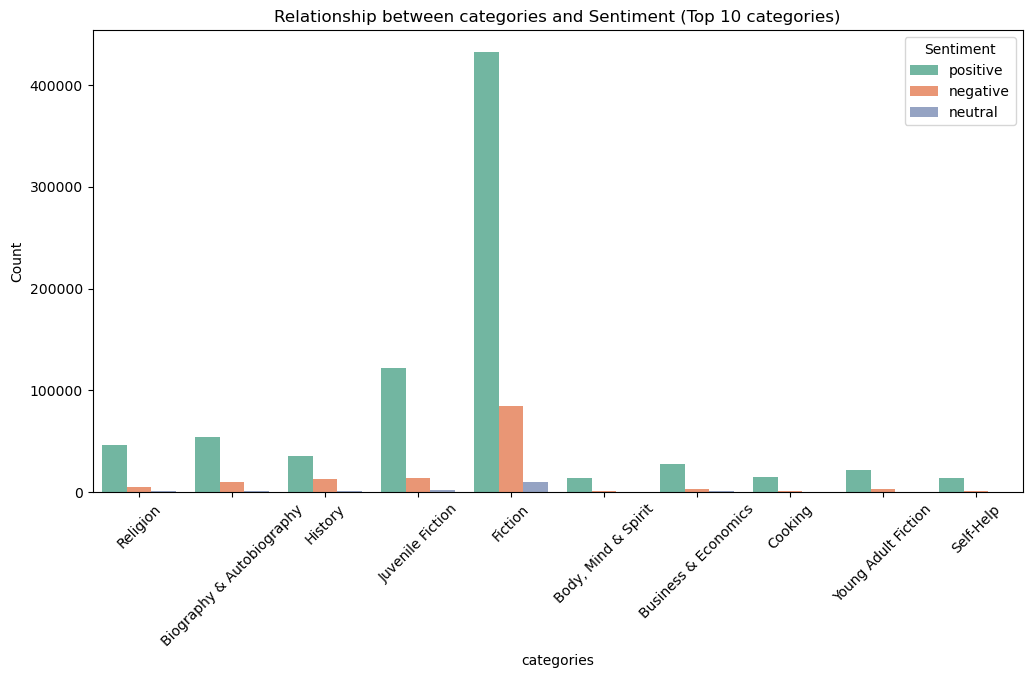

In [34]:
plt.figure(figsize=(12, 6))

top_10_categories = df['categories'].value_counts().head(10).index

df_top_10_categories = df[df['categories'].isin(top_10_categories)]

sns.countplot(x='categories', hue='Sentiment', data=df_top_10_countries, palette='Set2')
plt.title('Relationship between categories and Sentiment (Top 10 categories)')
plt.xlabel('categories')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

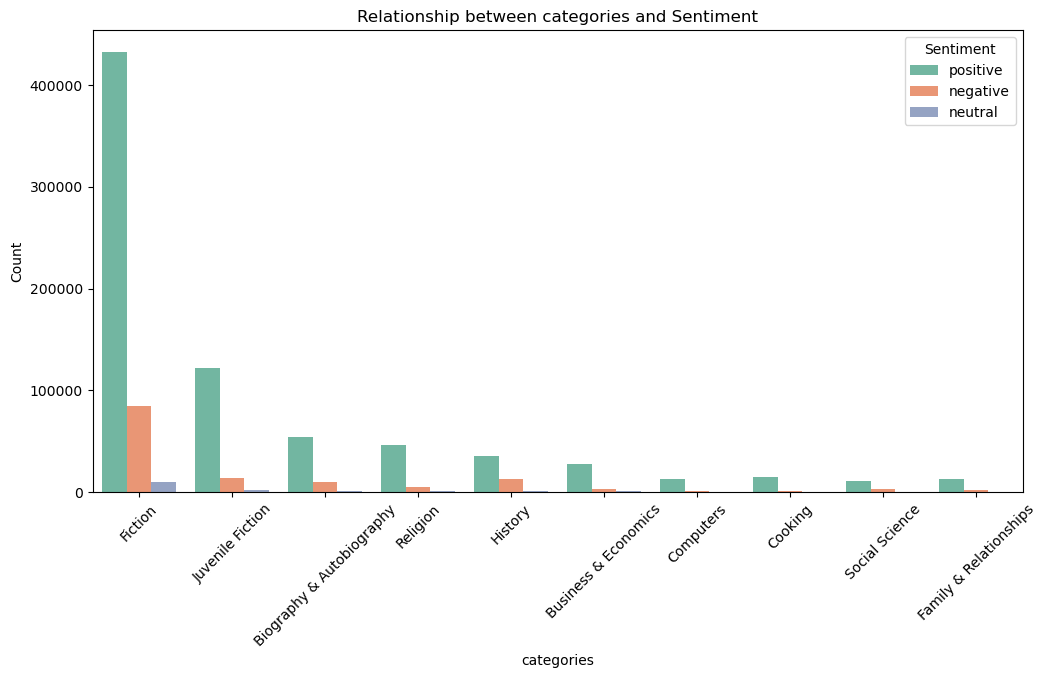

In [35]:
#Relationship between categories and Sentiment
plt.figure(figsize=(12, 6))
categories=['Fiction','Juvenile Fiction','Biography & Autobiography','Religion','History','Business & Economics','Computers','Cooking','Social Science','Family & Relationships']
# Create a stacked bar plot showing the count of each sentiment for each category
sns.countplot(x='categories', hue='Sentiment', data=df, palette='Set2', order=categories)
plt.title('Relationship between categories and Sentiment')
plt.xlabel('categories')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()
